# Práctica de Temperaturas
***
*Ismael Darias Darias*

A continuación, se presentan las celdas de código usadas para la realización de la práctica *Temperaturas* de la asignatura de instrumentación en geofísica y meteorología (meteorología). Cada celda de código cuenta con sus comentarios explicativos y celdas en markdwon que resumen el razonamiento seguido.

In [1]:
# Librerias de instalacion previa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Previsualización de los datos

En el archivo, <DESCRIPCIÓN_TEMPERATURA.CSV> nos indican como son los datos. A modo de resumen, se da las coordenadas geográficas, el nombre del lugar, la estación por la que han sido recogidos, el indicativo climatológico y la altitud, además de las temperaturas máximas y mínimas en cada uno de los días.

En cuanto al archivo, <MAESTRO_TEMPERATURA.CSV> contiene datos de tipo geográfico, posiblemente indicando que las coordenadas de longitud y latitud, estación o provincia, deben ser extraídas de ahí.

Por último, el archivo <TEMPERATURA_DIARIA.CSV> es el que contiene todos los datos de temperatura expresados en decimas de grados.

In [2]:
# Apertura del archivo de temperaturas diarias
temperaturas_diarias = pd.read_csv('TEMPERATURA_DIARIA.CSV', delimiter = ';', encoding='latin-1')

In [3]:
# Visualización de la cabecera
temperaturas_diarias.head()

,INDICATIVO,AÑO,MES,NOMBRE,ALTITUD,NOM_PROV,LONGITUD,LATITUD,DATUM,TMAX1,...,TMIN22,TMIN23,TMIN24,TMIN25,TMIN26,TMIN27,TMIN28,TMIN29,TMIN30,TMIN31
0,4258,1990,1,FUENTE OBEJUNA (CUENCA),571,CORDOBA,533292,381923,ETRS89,120.0,...,-10.0,-20.0,10.0,80.0,80.0,80.0,50.0,0.0,10.0,60.0
1,4258,1990,2,FUENTE OBEJUNA (CUENCA),571,CORDOBA,533292,381923,ETRS89,120.0,...,60.0,70.0,60.0,80.0,60.0,60.0,50.0,NaN,NaN,NaN
2,4258,1990,3,FUENTE OBEJUNA (CUENCA),571,CORDOBA,533292,381923,ETRS89,170.0,...,70.0,80.0,30.0,50.0,40.0,20.0,0.0,30.0,40.0,60.0
3,4258,1990,4,FUENTE OBEJUNA (CUENCA),571,CORDOBA,533292,381923,ETRS89,140.0,...,20.0,30.0,30.0,40.0,60.0,80.0,90.0,80.0,100.0,NaN
4,4258,1990,5,FUENTE OBEJUNA (CUENCA),571,CORDOBA,533292,381923,ETRS89,190.0,...,80.0,90.0,100.0,90.0,100.0,130.0,140.0,110.0,130.0,160.0


In [4]:
# Información acerca de las variables y el número de datos no nulos
temperaturas_diarias.info()

<class 'pandas.DataFrame'>
RangeIndex: 98137 entries, 0 to 98136
Data columns (total 71 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   INDICATIVO  98137 non-null  str    
 1   AÑO         98137 non-null  int64  
 2   MES         98137 non-null  int64  
 3   NOMBRE      98137 non-null  str    
 4   ALTITUD     98137 non-null  int64  
 5   NOM_PROV    98137 non-null  str    
 6   LONGITUD    98137 non-null  int64  
 7   LATITUD     98137 non-null  int64  
 8   DATUM       98137 non-null  str    
 9   TMAX1       96433 non-null  float64
 10  TMAX2       96424 non-null  float64
 11  TMAX3       96498 non-null  float64
 12  TMAX4       96486 non-null  float64
 13  TMAX5       96524 non-null  float64
 14  TMAX6       96506 non-null  float64
 15  TMAX7       96473 non-null  float64
 16  TMAX8       96490 non-null  float64
 17  TMAX9       96525 non-null  float64
 18  TMAX10      96561 non-null  float64
 19  TMAX11      96604 non-null  float64


In [5]:
# Descripción estadística genérica de cada una de las columnas
temperaturas_diarias.describe()

,AÑO,MES,ALTITUD,LONGITUD,LATITUD,TMAX1,TMAX2,TMAX3,TMAX4,TMAX5,...,TMIN22,TMIN23,TMIN24,TMIN25,TMIN26,TMIN27,TMIN28,TMIN29,TMIN30,TMIN31
count,98137.000000,98137.000000,98137.000000,98137.000000,98137.000000,96433.000000,96424.000000,96498.000000,96486.000000,96524.000000,...,96554.000000,96545.000000,96555.000000,96533.000000,96509.000000,96479.000000,96442.000000,90291.000000,88184.000000,55930.000000
mean,2004.974617,6.457870,397.747669,451622.634521,371200.653383,229.392490,229.551771,230.017793,230.132154,229.816212,...,112.562048,112.007323,112.278815,112.941346,112.284927,112.547197,112.668796,116.538193,118.758312,117.183908
std,9.079964,3.448266,359.866254,135864.831225,5708.455022,81.262465,81.025619,81.354582,82.083027,81.812086,...,63.586926,64.210273,64.360417,63.148766,62.672267,63.126638,63.600087,62.596308,61.789343,65.126969
min,1990.000000,1.000000,1.000000,149002.000000,355618.000000,-40.000000,-40.000000,-40.000000,-58.000000,-70.000000,...,-150.000000,-130.000000,-155.000000,-130.000000,-164.000000,-220.000000,-190.000000,-180.000000,-130.000000,-150.000000
25%,1997.000000,3.000000,66.000000,340242.000000,365117.000000,167.000000,165.000000,165.000000,165.000000,165.000000,...,70.000000,65.000000,65.000000,69.000000,68.000000,68.000000,65.000000,70.000000,74.000000,70.000000
50%,2005.000000,6.000000,320.000000,445362.000000,371802.000000,220.000000,220.000000,222.000000,220.000000,220.000000,...,110.000000,110.000000,111.000000,112.000000,110.000000,111.000000,110.000000,120.000000,120.000000,119.000000
75%,2013.000000,9.000000,649.000000,550482.000000,374607.000000,292.000000,295.000000,295.000000,295.000000,291.000000,...,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,165.000000,168.000000,170.000000
max,2021.000000,12.000000,2507.000000,731122.000000,382956.000000,480.000000,465.000000,465.000000,475.000000,470.000000,...,320.000000,330.000000,350.000000,325.000000,356.000000,362.000000,370.000000,380.000000,378.000000,332.000000


In [6]:
# Apertura de los datos de temperaturas maestro
temperaturas_maestro = pd.read_csv('MAESTRO_TEMPERATURA.CSV', delimiter = ';', encoding= 'latin-1')

In [7]:
# Mostrar cabecera
temperaturas_maestro.head()

,INDICATIVO,NOMBRE,NOM_PROV,NOM_MUNI,ALTITUD,LATITUD,LONGITUD,C_X,C_Y,DATUM,IND_SYN,ALTA,BAJA
0,4258,FUENTE OBEJUNA (CUENCA),CORDOBA,FUENTE OBEJUNA,571,381923,533292,276381,4244758,ETRS89,NaN,01/09/1949,NaN
1,4263X,VALSEQUILLO,CORDOBA,VALSEQUILLO,575,382434,521022,294767,4253863,ETRS89,NaN,01/05/2008,NaN
2,4267E,HINOJOSA DEL DUQUE (OBSERVATORIO),CORDOBA,HINOJOSA DEL DUQUE,540,382956,507492,314223,4263309,ETRS89,NaN,01/01/1973,30/06/2010
3,4267X,HINOJOSA DEL DUQUE-DEHESAS CORDOBESAS,CORDOBA,HINOJOSA DEL DUQUE,551,382955,507162,315030,4263272,ETRS89,8335.0,01/03/2000,NaN
4,4274,VILLARALTO,CORDOBA,VILLARALTO,583,382722,458582,326993,4258286,ETRS89,NaN,01/10/1949,NaN


Veamos cuantos años de datos tenemos, y que distintas provincias y estaciones tenemos, para ver que posibles preguntas nos podemos plantear

In [8]:
print(np.unique(temperaturas_diarias['NOMBRE']))
print(np.unique(temperaturas_diarias['AÑO']))
print(np.unique(temperaturas_maestro['NOM_PROV']))
print(np.unique(temperaturas_diarias['ALTITUD']))

['ABLA' 'ADRA          FARO' 'ADRA,C.NAUTICO' 'ADRA,CLUB NAÚTICO'
 "AGUADULCE 'COLEGIO'" 'AGUILAR (INSTITUTO)' 'AGUILAR (LAGUNA ZOÑAR)'
 'AGUILAR, LAGUNA ZOÑAR' 'ALAJAR' 'ALAJAR (AUTOMATICA)'
 'ALAJAR, CABEZO MOLINO' 'ALBOLOTE (CORTIJO ALBARRATE)' 'ALBONDON'
 'ALBORÁN,ISLA' 'ALBOX' 'ALCALA DE LOS GAZULES (PR.BARBATE)'
 'ALCALA DEL RIO (PEDRO ESPIGA)' 'ALCALA DEL RIO (TORRE VEGA)'
 'ALCALA GUADAIRA (RANILLA)' 'ALCALA LA REAL (CHARILLA)'
 'ALCALA LA REAL (CHG)' 'ALCALÁ LA REAL CHARILLA' 'ALDEIRE'
 'ALGARINEJO (AYUNTAMIENTO)' 'ALGARROBO (LA MAYORA)'
 'ALGARROBO, LA MAYORA' 'ALGECIRAS' 'ALHAMA DE ALMERIA'
 'ALHAMA DE GRANADA (PILAS DEDIL)'
 "ALHAURIN DE LA TORRE 'COLEGIO EL PINAR'"
 'ALHAURIN EL GRANDE (CAMINO FORESTAL)' 'ALMADEN PLATA (LAS NAVAS)'
 'ALMADEN PLATA, LAS NAVAS' 'ALMARGEN' 'ALMEDINILLA' 'ALMERÍA/AEROPUERTO'
 'ALMONASTER LA REAL' 'ALMONTE (ACEBUCHE)' 'ALMONTE (DOÑANA)'
 'ALMONTE (LA CAÑADA)' 'ALMONTE (LOS MIMBRALES)' 'ALMONTE (MARISMILLAS)'
 'ALMONTE, DOÑANA' 'ALMUÑECAR (EL ZA

Observando los datos, he voy decidido centrarme en un estudio a nivel estatal, en el que vamos a ver la tendencia de la temperatura mínima y máxima con los años para 4 niveles de alturas diferentes. Para ello, el procedimiento a seguir es el siguiente:
1) Agrupar los datos por altitud [0-500, 500-1000, 1000-1500,  >1500]
2) Calcular las temperaturas medias de la máxima y la mínima por año para cada nivel
3) Representar gráficamente y ajustar por mínimos cuadrados de forma lineal, de forma que podamos estimar la tendencia y el error


## Agrupación  por alturas

In [9]:
# Filtrado por alturas
df_low = temperaturas_diarias[temperaturas_diarias['ALTITUD'] <= 500] #0-500 m
df_med1 = temperaturas_diarias[(temperaturas_diarias['ALTITUD'] > 500) & (temperaturas_diarias['ALTITUD']<=1000)] # 500-1000 m
df_med2 = temperaturas_diarias[(temperaturas_diarias['ALTITUD'] > 1000) & (temperaturas_diarias['ALTITUD']<=1500)] # 1000-1500 m
df_high = temperaturas_diarias[temperaturas_diarias['ALTITUD'] > 1500] # >1500 m

## Calculo de temperaturas máximas y mínimas medias, por provincia y año

In [10]:
# Identificamos las columnas de temperatura
tmax_cols = [f'TMAX{i}' for i in range(1, 32)]
tmin_cols = [f'TMIN{i}' for i in range(1, 32)]

dfs = [df_low, df_med1, df_med2, df_high] # Lista con los dataframes para iterar

for i, df in enumerate(dfs): # Iteración sobre cada dataframe

# Calcular la media de cada fila en ºC
    df = df.copy()
    df['TMAX_MEDIA'] = df[tmax_cols].mean(axis=1) / 10
    df['TMIN_MEDIA'] = df[tmin_cols].mean(axis=1) / 10

# Agrupar por pronvincia y año reemplazando los dataframes originales
    dfs[i] = (df.groupby(['NOM_PROV', 'AÑO'])[['TMAX_MEDIA', 'TMIN_MEDIA']].mean().reset_index())

# Desempaquetamos los dataframes para su posterior manipulación
df_low, df_med1, df_med2, df_high = dfs

# Mostramos cabecera de ejemplo
df_low.head()

,NOM_PROV,AÑO,TMAX_MEDIA,TMIN_MEDIA
0,ALMERIA,1990,23.901237,14.145537
1,ALMERIA,1991,22.831024,13.379511
2,ALMERIA,1992,22.739771,13.268142
3,ALMERIA,1993,22.462008,13.092711
4,ALMERIA,1994,23.761554,14.470232


### Agrupación unicamente por años

In [11]:
dfs = [df_low, df_med1, df_med2, df_high] # Lista de dataframes

for i, df in enumerate(dfs): # Iteración sobre cada dataframe

    # Reemplazo de los dataframes originales
    dfs[i] = df.groupby('AÑO')[['TMAX_MEDIA', 'TMIN_MEDIA']].mean().reset_index()

df_low_anual, df_med1_anual, df_med2_anual, df_high_anual = dfs # Desempaquetamos

# Visualizamos uno de los dataframes
df_low_anual

,AÑO,TMAX_MEDIA,TMIN_MEDIA
0,1990,24.012354,12.589884
1,1991,23.029890,11.662886
2,1992,23.106974,11.294440
3,1993,22.628912,11.001792
4,1994,24.091668,11.786276
5,1995,24.254143,12.407614
6,1996,22.726848,12.004974
7,1997,23.428791,12.703412
8,1998,23.401643,12.073514
9,1999,23.452854,12.058891


## Tendencia de la temperatura con los años a nivel estatal para cada altura

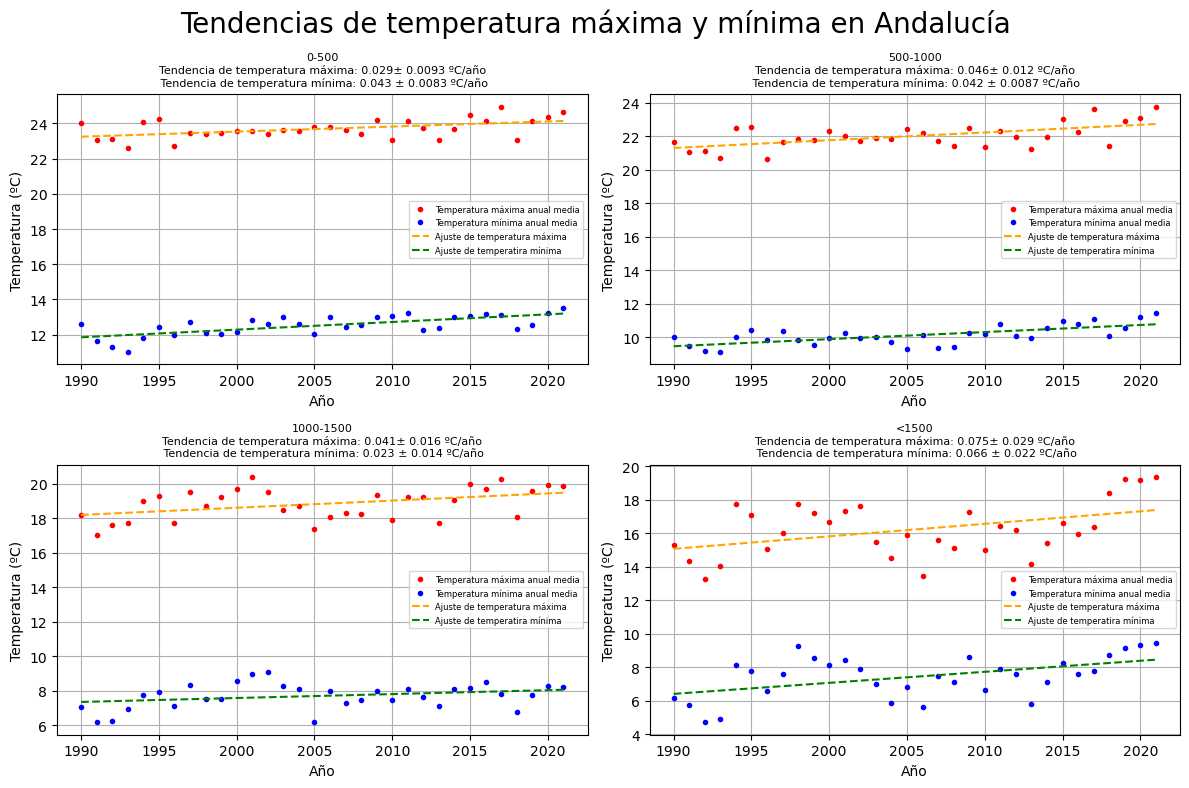

In [13]:
dfs = [df_low_anual, df_med1_anual, df_med2_anual, df_high_anual] # Lista con los dataframes

# Creamos las figuras
fig, axes = plt.subplots(2, 2, figsize = (12,8))
axes = axes.flatten()

# Titulos de cada subfigura
titulos = ['0-500', '500-1000', '1000-1500', '<1500']

# Repetimos para cada dataframe
for i, df in enumerate(dfs):

    x = df['AÑO'] # Asociamos la variable x a los años

    # Guardamos las temperaturas en variables
    tmax = df['TMAX_MEDIA']
    tmin = df['TMIN_MEDIA']

    # Calculamos ajuste y la matriz de covarianza
    p_max, cov_max = np.polyfit(x, tmax , deg = 1, cov = True)
    p_min, cov_min = np.polyfit(x, tmin , deg = 1, cov = True)

    # Parámetros del ajuste de la temperatura máxima
    m_max = p_max[0]
    n_max = p_max[1]

    # Parámetros del ajuste de la temperatura mínima
    m_min = p_min[0]
    n_min = p_min[1]

    # Errores asociados a partir de la matriz de covarianza
    error_m_max = np.sqrt(cov_max[0,0])
    error_m_min = np.sqrt(cov_min[0,0])

    # Funciones para representar rectas de ajustes
    def pol_max(x):
        return m_max*x+n_max


    def pol_min(x):
        return m_min*x + n_min 

    # Subplot sobre el que se va a representar
    ax = axes[i]

    # Representamos
    ax.plot(x, tmax, '.r', label = 'Temperatura máxima anual media')
    ax.plot(x, tmin, '.b', label = 'Temperatura mínima anual media')
    ax.plot(x, pol_max(x), '--',color = 'orange', label = 'Ajuste de temperatura máxima')
    ax.plot(x, pol_min(x), '--g', label = 'Ajuste de temperatira mínima')

    # Comentario con las tendencias de temperatura y su error, usando solo dos cifras significativas
    texto = f'Tendencia de temperatura máxima: {m_max:.2g}± {error_m_max:.2g} ºC/año\n Tendencia de temperatura mínima: {m_min:.2g} ± {error_m_min:.2g} ºC/año'

    # Mejora de la estética de las gráficas
    ax.set_ylabel('Temperatura (ºC)')
    ax.set_xlabel('Año')
    ax.set_title(f'{titulos[i]}\n{texto}', fontsize = 8)
    ax.legend(loc = 'best', fontsize = 6)
    ax.grid()

fig.suptitle('Tendencias de temperatura máxima y mínima en Andalucía', fontsize = 20)# Título genérico
plt.tight_layout() # Mejorar estética
plt.show() # Mostrar

plt.savefig('./Informe/Imagenes/Tendencias.png') # Guardamos

plt.close() # Cerramos la figura (Realmente no es necesario a menos que se pretenda modificar sobre la imagen con el propio código abierto (se almacena como una variable abierta))

Como última comprobación para entender los errores asociados, se ha contado la cantidad de datos faltantes en el dataframe original

In [14]:
faltantes = temperaturas_diarias.isna().sum()
print(faltantes[faltantes > 0])

TMAX1      1704
TMAX2      1713
TMAX3      1639
TMAX4      1651
TMAX5      1613
          ...  
TMIN27     1658
TMIN28     1695
TMIN29     7846
TMIN30     9953
TMIN31    42207
Length: 62, dtype: int64


 Vemos que pueden faltar hasta casi 10000 datos, lo que da lugar a que la estadística no sea muy robusta. Aún así, sigue siendo manejable trabajar con ella.